# Praktikum Data Mining — Evaluasi Model Klasifikasi
**Confusion Matrix, Accuracy, Precision, Recall, dan F1-Score**
**Studi Kasus: Prediksi Kelayakan Penerima Beasiswa (Data Dummy)**

---
**Kelompok 8**

| No | Nama | NIM |
|----|------|-----|
| 1 | Ahmad Naufal Azzuhdi | 24343029 |
| 2 | Dealexa Fatika Dzikra | 24343031 |

Program Studi Informatika, Fakultas Teknik — Universitas Negeri Padang (UNP)

---
**Tentang studi kasus.** Modul asli memakai deteksi fraud. Pada notebook ini kasusnya diganti menjadi *prediksi kelayakan penerima beasiswa*. Pemetaannya:

| Modul (fraud) | Notebook ini (beasiswa) |
|---|---|
| Kelas positif `isFraud = 1` | `isLayak = 1` (pendaftar layak menerima beasiswa) |
| FN: fraud lolos | FN: pendaftar layak **tidak terdeteksi** (kehilangan kesempatan) |
| FP: transaksi normal diberi alarm | FP: pendaftar tidak layak **diprediksi layak** (beasiswa salah sasaran) |

Seluruh data adalah **data dummy hasil simulasi** (bukan data mahasiswa sebenarnya), dibangkitkan dengan `random_state`/seed tetap agar hasilnya dapat direproduksi.

## 4.1 Menyiapkan Dataset Sintetis

**Penjelasan:** Pada langkah ini dibangkitkan 500 data pendaftar beasiswa. Fitur yang dipakai:

| Fitur | Keterangan |
|---|---|
| `ipk` | IPK pendaftar (2,00–4,00) |
| `penghasilan_ortu` | Penghasilan orang tua per bulan (juta rupiah, simulasi) |
| `jumlah_tanggungan` | Jumlah tanggungan keluarga (1–6) |
| `prestasi` | Memiliki prestasi akademik/non-akademik (0/1) |
| `aktif_organisasi` | Aktif berorganisasi (0/1) |
| `isLayak` | **Label target** (0 = tidak layak, 1 = layak) |

Label dibuat dari skor logistik: IPK tinggi, penghasilan orang tua rendah, tanggungan banyak, memiliki prestasi, dan aktif organisasi meningkatkan peluang layak. Hasilnya kelas **layak adalah minoritas** (data tidak seimbang), sama seperti fraud yang jarang pada modul.

In [1]:
import numpy as np
import pandas as pd

# Generator angka acak dengan seed tetap supaya hasil selalu sama (reproducible)
rng = np.random.default_rng(42)
n = 500  # jumlah pendaftar beasiswa

# --- Membangkitkan fitur ---
ipk = np.clip(rng.normal(3.2, 0.4, n), 2.0, 4.0)       # IPK ~ normal, dibatasi 2.0-4.0
penghasilan_ortu = rng.lognormal(mean=1.6, sigma=0.6, size=n)  # juta rupiah/bulan (miring ke kanan)
jumlah_tanggungan = rng.integers(1, 7, n)               # 1 sampai 6 orang
prestasi = rng.binomial(1, 0.20, n)                     # 20% punya prestasi
aktif_organisasi = rng.binomial(1, 0.30, n)             # 30% aktif organisasi

# --- Skor kelayakan (model logistik) ---
score = (-3.6
         + 0.9 * (ipk >= 3.5)
         + 1.5 * (ipk - 3.0)
         - 0.12 * penghasilan_ortu
         + 0.3 * jumlah_tanggungan
         + 1.0 * prestasi
         + 0.5 * aktif_organisasi)
prob = 1 / (1 + np.exp(-score))      # ubah skor menjadi probabilitas (sigmoid)
isLayak = rng.binomial(1, prob)      # tarik label 0/1 sesuai probabilitas

# --- Susun menjadi DataFrame ---
df = pd.DataFrame({
    'ipk': ipk.round(2),
    'penghasilan_ortu': penghasilan_ortu.round(2),
    'jumlah_tanggungan': jumlah_tanggungan,
    'prestasi': prestasi,
    'aktif_organisasi': aktif_organisasi,
    'isLayak': isLayak
})

# Simpan dataset ke file CSV
df.to_csv('dataset_beasiswa.csv', index=False)

print(df.head())
print('\nDistribusi kelas:')
print(df['isLayak'].value_counts())
print('\nProporsi layak: {:.1%}'.format(df['isLayak'].mean()))

    ipk  penghasilan_ortu  jumlah_tanggungan  prestasi  aktif_organisasi  \
0  3.32             11.23                  2         1                 1   
1  2.78              8.47                  4         0                 0   
2  3.50              3.22                  3         0                 0   
3  3.58              2.01                  3         0                 1   
4  2.42              0.84                  5         0                 0   

   isLayak  
0        0  
1        0  
2        0  
3        0  
4        0  

Distribusi kelas:
isLayak
0    438
1     62
Name: count, dtype: int64

Proporsi layak: 12.4%


**Penjelasan kode 4.1:**
- `np.random.default_rng(42)` membuat generator acak dengan seed 42, sehingga data selalu sama setiap dijalankan.
- `ipk`, `penghasilan_ortu`, `jumlah_tanggungan`, `prestasi`, `aktif_organisasi` adalah fitur yang dibangkitkan dengan distribusi berbeda (normal, lognormal, uniform diskrit, binomial).
- `score` menggabungkan fitur dengan bobot tertentu; tanda negatif pada `penghasilan_ortu` berarti makin tinggi penghasilan, makin kecil peluang layak.
- `1 / (1 + np.exp(-score))` (fungsi sigmoid) mengubah skor menjadi probabilitas 0–1, lalu `rng.binomial(1, prob)` menentukan label akhir.
- `df.to_csv(...)` menyimpan dataset ke `dataset_beasiswa.csv`.
- `value_counts()` menampilkan jumlah tiap kelas. Perhatikan jumlah kelas layak jauh lebih sedikit daripada tidak layak.

## 4.2 Membagi Data dan Melatih Model

**Penjelasan:** Data dibagi menjadi data latih (70%) dan data uji (30%). Model Decision Tree dilatih pada data latih, lalu dipakai memprediksi data uji yang belum pernah dilihat model.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Pisahkan fitur (X) dan target (y)
X = df.drop(columns='isLayak')
y = df['isLayak']

# Bagi data: 70% latih, 30% uji; stratify menjaga proporsi kelas tetap sama
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

# Decision Tree dengan kedalaman maksimum 4 dan bobot kelas seimbang
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)      # latih model
y_pred = model.predict(X_test)   # prediksi data uji

print('Data latih:', len(y_train))
print('Data uji:', len(y_test))
print('Jumlah layak di data uji:', int(y_test.sum()))

Data latih: 350
Data uji: 150
Jumlah layak di data uji: 19


**Penjelasan kode 4.2:**
- `X` berisi semua kolom fitur, `y` berisi label `isLayak`.
- `train_test_split(..., test_size=0.30)` menyisakan 30% data (150 baris) sebagai data uji.
- `stratify=y` memastikan proporsi layak/tidak layak pada data latih dan uji sama dengan data asli.
- `max_depth=4` membatasi kedalaman pohon agar tidak overfitting.
- `class_weight='balanced'` memberi bobot lebih besar pada kelas minoritas (layak) agar model tidak mengabaikannya.
- `fit()` melatih model, `predict()` menghasilkan `y_pred` (label prediksi) untuk data uji.

## 4.3 Menghitung Confusion Matrix

**Penjelasan:** Confusion matrix membandingkan label aktual (`y_test`) dengan prediksi (`y_pred`). Dengan `labels=[0,1]`, susunannya `[[TN, FP], [FN, TP]]`.

In [3]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()   # ratakan matriks menjadi empat angka

print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[87 44]
 [ 6 13]]
TP=13, TN=87, FP=44, FN=6


**Penjelasan kode 4.3:**
- `confusion_matrix(..., labels=[0,1])` menghasilkan matriks 2×2 dengan baris = aktual, kolom = prediksi.
- `cm.ravel()` meratakan matriks sesuai urutan `TN, FP, FN, TP`.
- **TP**: pendaftar layak yang diprediksi layak. **TN**: tidak layak diprediksi tidak layak. **FP**: tidak layak tetapi diprediksi layak (salah sasaran). **FN**: layak tetapi diprediksi tidak layak (peluang hilang).
- Nilai-nilai ini dibaca dari output eksekusi, bukan diasumsikan.

## 4.4 Perhitungan Manual dan Verifikasi

**Penjelasan:** Empat metrik dihitung manual dari TP, TN, FP, FN, lalu diverifikasi dengan fungsi scikit-learn. Keduanya harus sama.

In [4]:
# --- Perhitungan manual (rumus pada modul) ---
accuracy  = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall    = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print(f'Manual  -> Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')

# --- Verifikasi dengan scikit-learn ---
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc_sk = accuracy_score(y_test, y_pred)
pre_sk = precision_score(y_test, y_pred, zero_division=0)
rec_sk = recall_score(y_test, y_pred, zero_division=0)
f1_sk  = f1_score(y_test, y_pred, zero_division=0)
print(f'sklearn -> Accuracy={acc_sk:.3f}; Precision={pre_sk:.3f}; Recall={rec_sk:.3f}; F1={f1_sk:.3f}')

# Cek kesesuaian
print('Hasil manual sama dengan sklearn:',
      np.allclose([accuracy, precision, recall, f1], [acc_sk, pre_sk, rec_sk, f1_sk]))

Manual  -> Accuracy=0.667; Precision=0.228; Recall=0.684; F1=0.342
sklearn -> Accuracy=0.667; Precision=0.228; Recall=0.684; F1=0.342
Hasil manual sama dengan sklearn: True


**Penjelasan kode 4.4:**
- **Accuracy** = (TP+TN) / total: proporsi seluruh prediksi yang benar.
- **Precision** = TP / (TP+FP): dari yang diprediksi layak, berapa yang benar-benar layak.
- **Recall** = TP / (TP+FN): dari seluruh pendaftar layak, berapa yang berhasil ditemukan.
- **F1-score** = rata-rata harmonik precision dan recall.
- Kondisi `if tp + fp else 0` mencegah pembagian dengan nol.
- `np.allclose(...)` mengecek apakah hasil manual sama dengan fungsi scikit-learn; hasilnya `True` bila sesuai.

## 4.5 Visualisasi Confusion Matrix

**Penjelasan:** Confusion matrix ditampilkan sebagai gambar agar mudah dibaca.

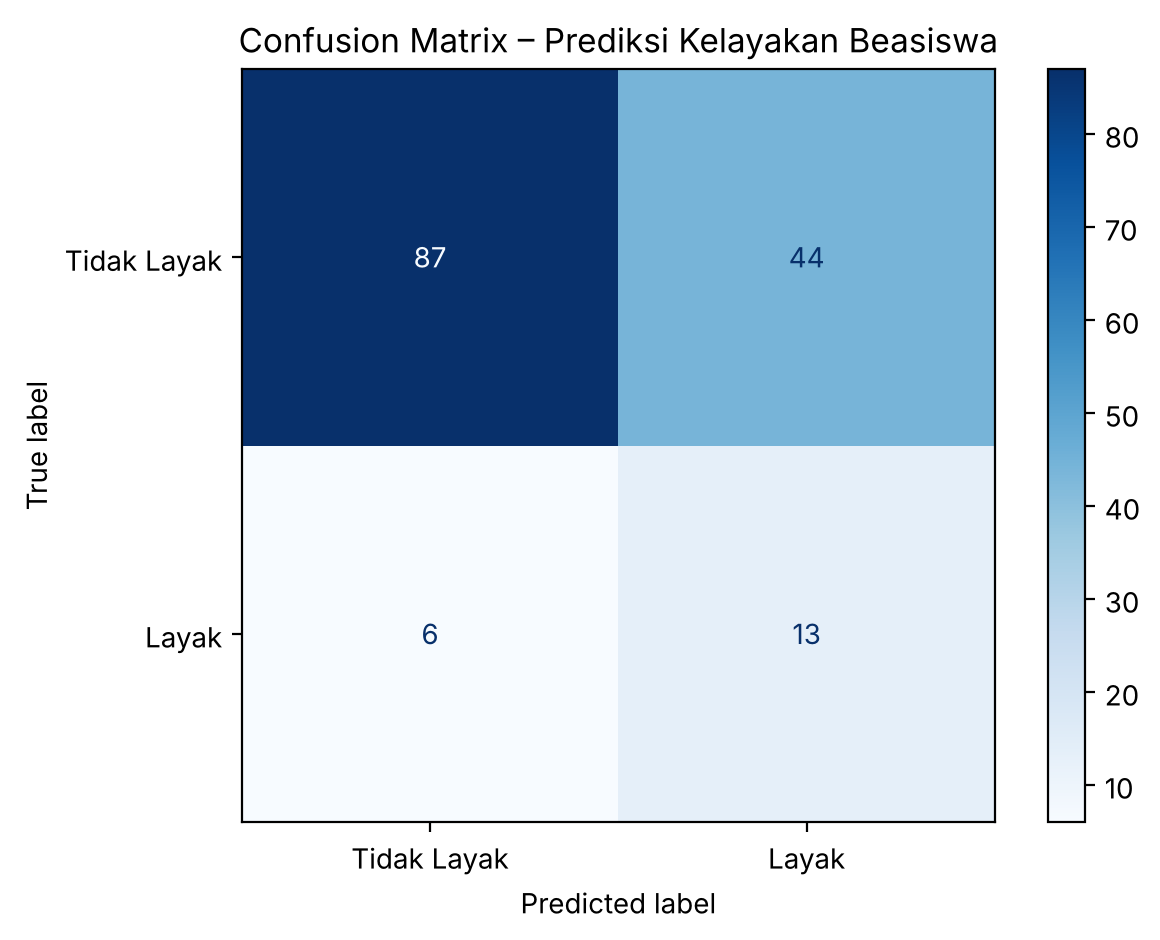

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Tidak Layak', 'Layak']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Prediksi Kelayakan Beasiswa')
plt.tight_layout()
plt.show()

**Penjelasan kode 4.5:**
- `ConfusionMatrixDisplay` menggambar `cm` sebagai heatmap; sumbu vertikal = label aktual, sumbu horizontal = label prediksi.
- `cmap='Blues'` mewarnai sel; makin pekat berarti makin banyak data.
- `values_format='d'` menampilkan angka sebagai bilangan bulat.
- Diagonal utama (kiri atas–kanan bawah) adalah prediksi benar (TN dan TP); sel di luar diagonal adalah kesalahan (FP dan FN).

## 4.6 Interpretasi dan Studi Kasus

**Penjelasan:** Hasil confusion matrix diterjemahkan ke konteks beasiswa.

In [6]:
print(f'''Interpretasi hasil pada data uji ({len(y_test)} pendaftar):
- TP = {tp}: pendaftar layak yang berhasil diprediksi layak.
- TN = {tn}: pendaftar tidak layak yang benar diprediksi tidak layak.
- FP = {fp}: pendaftar tidak layak yang diprediksi layak (beasiswa berpotensi salah sasaran).
- FN = {fn}: pendaftar layak yang diprediksi tidak layak (kehilangan kesempatan menerima beasiswa).
''')
print(f'Dari {tp+fn} pendaftar yang sebenarnya layak, {tp} berhasil ditemukan (recall = {recall:.1%}).')
print(f'Dari {tp+fp} pendaftar yang diprediksi layak, {tp} benar-benar layak (precision = {precision:.1%}).')

Interpretasi hasil pada data uji (150 pendaftar):
- TP = 13: pendaftar layak yang berhasil diprediksi layak.
- TN = 87: pendaftar tidak layak yang benar diprediksi tidak layak.
- FP = 44: pendaftar tidak layak yang diprediksi layak (beasiswa berpotensi salah sasaran).
- FN = 6: pendaftar layak yang diprediksi tidak layak (kehilangan kesempatan menerima beasiswa).

Dari 19 pendaftar yang sebenarnya layak, 13 berhasil ditemukan (recall = 68.4%).
Dari 57 pendaftar yang diprediksi layak, 13 benar-benar layak (precision = 22.8%).


**Penjelasan kode 4.6:** Kode ini mencetak makna tiap sel confusion matrix berdasarkan angka aktual dari output.

**Analisis:** Pada seleksi beasiswa, **FN** berarti pendaftar yang berhak justru tersingkir, sehingga mahasiswa berprestasi/membutuhkan kehilangan kesempatan. **FP** berarti beasiswa diberikan kepada yang kurang berhak, sehingga kuota terpakai tidak tepat. Recall tinggi mengurangi FN tetapi dapat menambah FP. Pemilihan metrik harus mempertimbangkan biaya masing-masing kesalahan.

## 4.7 Eksperimen: Baseline Semua "Tidak Layak"

**Penjelasan:** Baseline adalah "model" sederhana yang selalu memprediksi kelas mayoritas (tidak layak). Ini menunjukkan mengapa accuracy saja bisa menyesatkan pada data tidak seimbang.

In [7]:
from sklearn.metrics import classification_report

# Baseline: semua pendaftar diprediksi tidak layak (0)
baseline = np.zeros(len(y_test), dtype=int)

print('Baseline accuracy:', round(accuracy_score(y_test, baseline), 3))
print('\nLaporan klasifikasi — Baseline (semua tidak layak):')
print(classification_report(y_test, baseline, labels=[0, 1],
                            target_names=['Tidak Layak', 'Layak'], zero_division=0))

print('Laporan klasifikasi — Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=['Tidak Layak', 'Layak'], zero_division=0))

Baseline accuracy: 0.873

Laporan klasifikasi — Baseline (semua tidak layak):
              precision    recall  f1-score   support

 Tidak Layak       0.87      1.00      0.93       131
       Layak       0.00      0.00      0.00        19

    accuracy                           0.87       150
   macro avg       0.44      0.50      0.47       150
weighted avg       0.76      0.87      0.81       150

Laporan klasifikasi — Decision Tree:
              precision    recall  f1-score   support

 Tidak Layak       0.94      0.66      0.78       131
       Layak       0.23      0.68      0.34        19

    accuracy                           0.67       150
   macro avg       0.58      0.67      0.56       150
weighted avg       0.85      0.67      0.72       150



**Penjelasan kode 4.7:**
- `np.zeros(...)` membuat prediksi 0 untuk semua data uji (selalu "tidak layak").
- `classification_report` menampilkan precision, recall, F1, dan support (jumlah data) untuk setiap kelas.
- `zero_division=0` mencegah error/peringatan ketika model tidak pernah memprediksi suatu kelas.

**Analisis:** Baseline dapat memperoleh accuracy tinggi karena mayoritas pendaftar memang tidak layak, tetapi **recall kelas layak = 0**: tidak ada satu pun pendaftar layak yang ditemukan. Karena itu pada data tidak seimbang, accuracy harus dilengkapi precision, recall, dan F1 pada kelas minoritas. Bandingkan dengan recall kelas layak pada Decision Tree di atas.

## 4.8 Eksperimen: Pengaruh Ambang Prediksi (Threshold)

**Penjelasan:** Decision Tree menghasilkan probabilitas kelas. Ambang (threshold) menentukan batas probabilitas minimal agar pendaftar diprediksi layak. Empat ambang diuji: 0,2; 0,4; 0,5; 0,7.

In [8]:
# Probabilitas kelas "layak" (1) untuk data uji
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

hasil = []
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)   # layak jika probabilitas >= threshold
    p = precision_score(y_test, pred, zero_division=0)
    r = recall_score(y_test, pred, zero_division=0)
    print(threshold, 'precision=', round(p, 3), 'recall=', round(r, 3))
    hasil.append({'Threshold': threshold, 'Precision': round(p, 3), 'Recall': round(r, 3)})

# Tabel ringkasan
tabel_threshold = pd.DataFrame(hasil)
print('\nTabel precision dan recall:')
print(tabel_threshold.to_string(index=False))

0.2 precision= 0.162 recall= 0.842
0.4 precision= 0.228 recall= 0.684
0.5 precision= 0.228 recall= 0.684
0.7 precision= 0.333 recall= 0.158

Tabel precision dan recall:
 Threshold  Precision  Recall
       0.2      0.162   0.842
       0.4      0.228   0.684
       0.5      0.228   0.684
       0.7      0.333   0.158


**Penjelasan kode 4.8:**
- `predict_proba(...)` menghasilkan probabilitas tiap kelas; diambil kolom kelas 1 (layak).
- `(y_prob >= threshold).astype(int)` mengubah probabilitas menjadi label: 1 bila probabilitas ≥ threshold.
- Loop menghitung precision dan recall untuk setiap threshold, lalu hasilnya dirangkum dalam tabel.

**Analisis:** Menurunkan threshold umumnya membuat lebih banyak pendaftar diprediksi layak, sehingga recall cenderung naik dan precision cenderung turun. Pada dataset kecil dengan pohon dangkal, probabilitas hanya mengambil beberapa nilai diskret, sehingga polanya bisa tidak monoton; gunakan angka pada tabel di atas sebagai dasar kesimpulan. Bila biaya FN (pendaftar layak tersingkir) dinilai lebih besar daripada FP, pilih threshold yang menghasilkan recall tertinggi dengan precision yang masih dapat diterima.

## Ringkasan

Notebook ini mencakup langkah 4.1–4.8 modul: pembangkitan dataset beasiswa dummy, pembagian data, pelatihan Decision Tree, confusion matrix, perhitungan metrik manual dan verifikasi scikit-learn, visualisasi, interpretasi, eksperimen baseline, dan eksperimen threshold. Dataset tersimpan pada `dataset_beasiswa.csv`.